# 03. Segmentación de hogares
Óscar - Inteligencia de Negocio

Agrupamos los hogares sobre el mapa de UMAP, analizamos las características de cada grupo y los validamos con los cupones y la demografía.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.stats import chi2_contingency

datos = Path("../datos")
salidas = Path("../salidas")
figuras = salidas / "figuras"
figuras.mkdir(parents=True, exist_ok=True)

COLUMNAS = ["n_visitas", "gasto_medio_cesta", "recencia", "variedad",
            "pct_marca_propia", "pct_fresco", "pct_descuento"]

## 1. Cargar los datos
Unimos los mapas con los valores originales de los hogares por household_key.

In [2]:
mapas = pd.read_csv(salidas / "mapas.csv")
sin_escalar = pd.read_csv(salidas / "hogares_sin_escalar.csv")
hogares = pd.read_csv(salidas / "hogares.csv")

base = mapas.merge(sin_escalar, on="household_key", how="inner")

print("Hogares en mapas:", len(mapas))
print("Hogares en la unión:", len(base))
print("Mismos hogares que hogares.csv:",
      set(base["household_key"]) == set(hogares["household_key"]))
print("Valores ausentes:", base.isna().sum().sum())

Hogares en mapas: 2475
Hogares en la unión: 2475
Mismos hogares que hogares.csv: True
Valores ausentes: 0


## 2. Número de grupos
Utilizamos KMeans con 3 a 6 grupos sobre UMAP e Isomap y los comparamos con el coeficiente de silueta.

In [3]:
resultados = []
for mapa in ["umap", "isomap"]:
    X = base[[f"{mapa}_1", f"{mapa}_2"]].values
    for k in range(3, 7):
        etiquetas = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
        resultados.append({"mapa": mapa, "k": k,
                           "silueta": round(silhouette_score(X, etiquetas), 3)})

tabla_k = pd.DataFrame(resultados)
print(tabla_k.pivot(index="k", columns="mapa", values="silueta"))

mapa  isomap   umap
k                  
3      0.353  0.397
4      0.323  0.380
5      0.328  0.380
6      0.339  0.389


Utilizamos UMAP con 4 grupos. Con 3 la silueta es ligeramente superior (0,397 frente a 0,380), pero con 4 se distinguen mejor los comportamientos de compra.

In [ ]:
MAPA = "umap"   # mapa elegido
K = 4           # número de grupos

X = base[[f"{MAPA}_1", f"{MAPA}_2"]].values
base["segmento"] = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(X)
print(base["segmento"].value_counts().sort_index())

segmento
0    663
1    526
2    629
3    657
Name: count, dtype: int64


## 3. Perfil de cada segmento
Calculamos la media de las variables originales de cada grupo y su diferencia con la media general.

          n_visitas  gasto_medio_cesta  recencia  variedad  pct_marca_propia  \
segmento                                                                       
0           144.351             44.901     5.860   158.581             0.183   
1            52.745             30.121    33.527    85.762             0.164   
2            39.595             26.817    51.267    76.485             0.274   
3           162.787             26.199     5.461   135.712             0.300   

          pct_fresco  pct_descuento  n_hogares  
segmento                                        
0              0.238          0.155        663  
1              0.184          0.155        526  
2              0.315          0.242        629  
3              0.274          0.221        657  


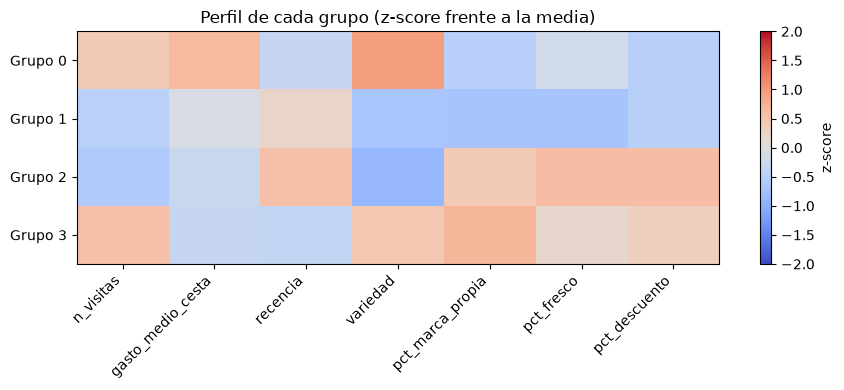

In [5]:
perfil = base.groupby("segmento")[COLUMNAS].mean()
perfil["n_hogares"] = base.groupby("segmento").size()
print(perfil.round(3))

zscore = (perfil[COLUMNAS] - base[COLUMNAS].mean()) / base[COLUMNAS].std()

fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(zscore.values, cmap="coolwarm", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(COLUMNAS)), COLUMNAS, rotation=45, ha="right")
ax.set_yticks(range(len(zscore)), [f"Grupo {g}" for g in zscore.index])
ax.set_title("Perfil de cada grupo (z-score frente a la media)")
plt.colorbar(im, label="z-score")
plt.tight_layout()
plt.savefig(figuras / "03_perfiles.png", dpi=150)
plt.show()

- Grupo 0: compradores de cestas grandes.
- Grupo 1: compradores ocasionales.
- Grupo 2: compradores de productos frescos.
- Grupo 3: compradores frecuentes de marca propia.

## 4. Validación con cupones
Solo tenemos en cuenta los hogares que recibieron campañas, para que la comparación sea justa.

In [ ]:
cupones = pd.read_csv(datos / "coupon_redempt.csv")
campanas = pd.read_csv(datos / "campaign_table.csv")
print("coupon_redempt:", cupones.columns.tolist())
print("campaign_table:", campanas.columns.tolist())

recibidas = campanas[["household_key", "CAMPAIGN"]].drop_duplicates()
canjes = cupones[["household_key", "CAMPAIGN"]].drop_duplicates()
canjes_validos = canjes.merge(recibidas, on=["household_key", "CAMPAIGN"])

base["recibio_campana"] = base["household_key"].isin(recibidas["household_key"])
base["canjeo"] = base["household_key"].isin(canjes_validos["household_key"])
rec = base[base["recibio_campana"]].copy()

tabla_cupones = rec.groupby("segmento").agg(
    receptores=("household_key", "size"),
    canjeadores=("canjeo", "sum"))
tabla_cupones["pct_canje"] = (100 * tabla_cupones["canjeadores"]
                              / tabla_cupones["receptores"]).round(1)
print(tabla_cupones)
print("Media global:", round(100 * rec["canjeo"].mean(), 1), "%")

          receptores  canjeadores  pct_canje
segmento                                    
0                630          225       35.7
1                211           18        8.5
2                170           23       13.5
3                573          168       29.3
Media global: 27.4 %


p-valor: 0.0


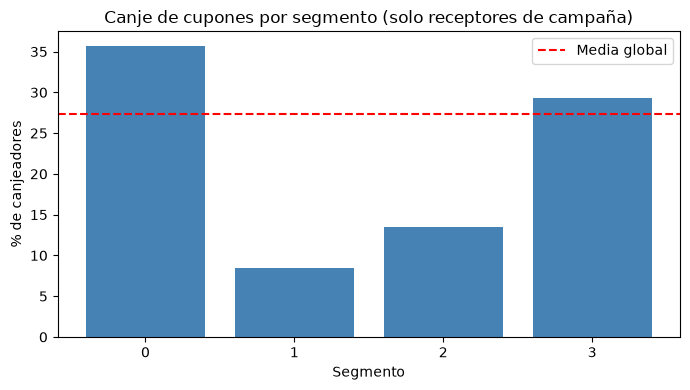

In [ ]:
tabla = pd.crosstab(rec["segmento"], rec["canjeo"])
chi2, p, dof, _ = chi2_contingency(tabla)
print("p-valor:", p)               # sin redondear
print("chi2:", round(chi2, 2), "| grados de libertad:", dof)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(tabla_cupones.index.astype(str), tabla_cupones["pct_canje"], color="steelblue")
ax.axhline(100 * rec["canjeo"].mean(), color="red", linestyle="--", label="Media global")
ax.set_xlabel("Segmento")
ax.set_ylabel("% de canjeadores")
ax.set_title("Canje de cupones por segmento (solo receptores de campaña)")
ax.legend()
plt.tight_layout()
plt.savefig(figuras / "03_cupones.png", dpi=150)
plt.show()

## 5. Validación con demografía
Solo 801 hogares tienen datos demográficos, así que lo usamos para confirmar, no para crear los grupos.

In [ ]:
demo = pd.read_csv(datos / "hh_demographic.csv")
print("hh_demographic:", demo.columns.tolist())   # confirma que existe AGE_DESC
con_demo = base.merge(demo, on="household_key", how="inner")

print("Hogares con demografía por segmento:")
print(con_demo["segmento"].value_counts().sort_index())
print((pd.crosstab(con_demo["segmento"], con_demo["AGE_DESC"],
                   normalize="index") * 100).round(1))

Hogares con demografía por segmento:
segmento
0    398
1     58
2     48
3    297
Name: count, dtype: int64
AGE_DESC  19-24  25-34  35-44  45-54  55-64   65+
segmento                                         
0           5.3   20.1   27.4   33.2    7.3   6.8
1           6.9   12.1   19.0   41.4    3.4  17.2
2           4.2   18.8   25.0   25.0   10.4  16.7
3           6.4   15.5   20.9   40.4    7.7   9.1


## 6. Guardar los segmentos
Guardamos el segmento de cada hogar en segmentos.csv y el mapa coloreado por grupos.

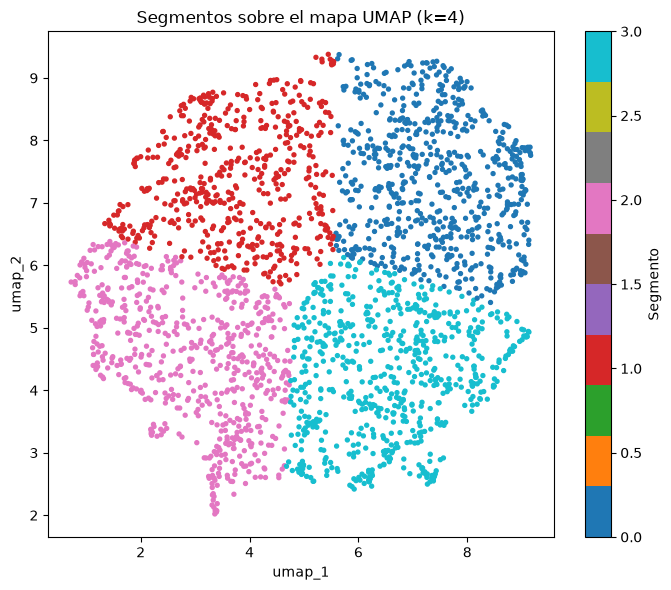

Filas guardadas: 2475


In [9]:
base[["household_key", "segmento"]].to_csv(salidas / "segmentos.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(base[f"{MAPA}_1"], base[f"{MAPA}_2"], c=base["segmento"],
                cmap="tab10", s=8)
ax.set_title(f"Segmentos sobre el mapa {MAPA.upper()} (k={K})")
ax.set_xlabel(f"{MAPA}_1")
ax.set_ylabel(f"{MAPA}_2")
plt.colorbar(sc, label="Segmento")
plt.tight_layout()
plt.savefig(figuras / "03_mapa_segmentos.png", dpi=150)
plt.show()

print("Filas guardadas:", len(pd.read_csv(salidas / "segmentos.csv")))